# 2.2 — Procesamiento: Monitor de Sequía (quincenal → mensual)

**Capa 3 del protocolo.** Toma los registros tidy de
`01_ingesta/1.2-monitor-sequia.ipynb` (municipio × fecha × categoría) y los
lleva a una serie mensual para Hermosillo.

## Entradas

| Ruta | Contenido |
|------|-----------|
| `data/interim/sonora_sequia/sonora_sequia_AAAA.csv` | Monitor de Sequía, municipios de Sonora: `CVE_MUN`, `fecha`, `categoria_sequia`, `severidad_num` |

## Salidas

- `data/interim/sequia/sequia_hermosillo_mensual.csv` (opcional, para
  revisión): `fecha_mes`, `severidad_sequia` (media 0–5), `categoria_sequia`
  (moda del mes).

> No guardar nada en `data/interim/sonora_sequia/`: `panel.py` lee **todos**
> los CSV de esa carpeta.

## Checklist

- [ ] Registros de Hermosillo (`CVE_MUN == 30`) en la ventana del panel.
- [ ] Registros por mes (1 o 2 quincenas) y si la frecuencia cambia entre años.
- [ ] Categorías sin mapeo en `config.DROUGHT_SEVERITY_MAP` (la ingesta las deja en 0).
- [ ] Moda del mes cuando las quincenas tienen categorías distintas (desempate).
- [ ] Meses del panel sin registro.

## Configuración e imports

In [1]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import pandas as pd
import matplotlib.pyplot as plt

from sonora_health_climate_eda.config import (
    DROUGHT_EXTREME_MIN_SEVERITY,
    DROUGHT_SEVERITY_MAP,
    INTERIM_DATA_DIR,
    PANEL_END_YEAR,
    PANEL_START_YEAR,
)
from sonora_health_climate_eda.panel import (
    _drought_records_hermosillo,  # privada: registros quincenales de Hermosillo
    drought_hermosillo,
    drought_hermosillo_weekly
)

from sonora_health_climate_eda.plots import plot_severidad_sequia_mensual, plot_severidad_sequia_semanal

OUT_DIR = INTERIM_DATA_DIR / "sequia"  # no usar sonora_sequia/ (ver nota arriba)

## Registros quincenales de Hermosillo

In [2]:
registros = _drought_records_hermosillo()
registros = registros[registros["fecha"].dt.year.between(PANEL_START_YEAR, PANEL_END_YEAR)].copy()
registros["fecha_mes"] = registros["fecha"].dt.to_period("M").dt.to_timestamp()
registros["fecha_semana"] = registros["fecha"].dt.to_period("W").dt.to_timestamp()
print(
    f"{len(registros)} registros, "
    f"{registros['fecha'].min():%Y-%m-%d} a {registros['fecha'].max():%Y-%m-%d}"
)
registros[["fecha", "fecha_mes", "fecha_semana", "categoria_sequia", "severidad_num"]].head()

144 registros, 2015-01-15 a 2020-12-31


,fecha,fecha_mes,fecha_semana,categoria_sequia,severidad_num
0,2015-01-15,2015-01-01,2015-01-12,NaN,0
1,2015-01-31,2015-01-01,2015-01-26,NaN,0
2,2015-02-15,2015-02-01,2015-02-09,NaN,0
3,2015-02-28,2015-02-01,2015-02-23,NaN,0
4,2015-03-15,2015-03-01,2015-03-09,NaN,0


## Frecuencia de la fuente

In [3]:
por_mes = registros.groupby("fecha_mes").size()
print("Meses según número de registros:")
print(por_mes.value_counts().sort_index())
print("\nRegistros por año:")
print(registros.groupby(registros["fecha"].dt.year).size())

Meses según número de registros:
2    72
Name: count, dtype: int64

Registros por año:
fecha
2015    24
2016    24
2017    24
2018    24
2019    24
2020    24
dtype: int64


## Categorías y mapeo a severidad

In [4]:
print(registros["categoria_sequia"].value_counts(dropna=False))

no_mapeadas = sorted(set(registros["categoria_sequia"].dropna().astype(str)) - set(DROUGHT_SEVERITY_MAP))
print("\nCategorías sin mapeo (la ingesta las convierte en severidad 0):", no_mapeadas)
print("Registros con categoría vacía:", registros["categoria_sequia"].isna().sum())

categoria_sequia
NaN    68
D0     41
D1     16
D2     13
D3      6
Name: count, dtype: int64

Categorías sin mapeo (la ingesta las convierte en severidad 0): []
Registros con categoría vacía: 68


## Serie mensual

In [5]:
sequia_mensual = drought_hermosillo()

esperados = pd.date_range(f"{PANEL_START_YEAR}-01-01", f"{PANEL_END_YEAR}-12-01", freq="MS")
faltantes = esperados.difference(sequia_mensual["fecha_mes"])
print("Meses del panel sin registro de sequía:", list(faltantes.strftime("%Y-%m")))
sequia_mensual.head()

Meses del panel sin registro de sequía: []


,fecha_mes,severidad_sequia,categoria_sequia
0,2015-01-01,0.0,NaN
1,2015-02-01,0.0,NaN
2,2015-03-01,0.0,NaN
3,2015-04-01,0.0,NaN
4,2015-05-01,0.0,NaN


## Moda con empate

Si un mes tiene dos quincenas con categorías distintas, la moda queda
empatada y `drought_hermosillo()` toma una sin un criterio explícito.

In [6]:
cats_mes = registros.groupby("fecha_mes")["categoria_sequia"].nunique()
meses_mixtos = cats_mes[cats_mes > 1].index
print(f"Meses con más de una categoría: {len(meses_mixtos)}")
registros[registros["fecha_mes"].isin(meses_mixtos)][["fecha", "categoria_sequia", "severidad_num"]]


Meses con más de una categoría: 10


,fecha,categoria_sequia,severidad_num
28,2016-03-15,D0,1
29,2016-03-31,D1,2
36,2016-07-15,D1,2
37,2016-07-31,D0,1
68,2017-11-15,D0,1
69,2017-11-30,D1,2
70,2017-12-15,D1,2
71,2017-12-31,D2,3
76,2018-03-15,D2,3
77,2018-03-31,D3,4


In [7]:
# TODO: definir el desempate (p. ej. quedarse con la categoría más severa del mes)
sev_max = registros.groupby("fecha_mes")["severidad_num"].max()
sequia_mensual["severidad_max_mes"] = sequia_mensual["fecha_mes"].map(sev_max)
sequia_mensual

,fecha_mes,severidad_sequia,categoria_sequia,severidad_max_mes
0,2015-01-01,0.0,NaN,0
1,2015-02-01,0.0,NaN,0
2,2015-03-01,0.0,NaN,0
3,2015-04-01,0.0,NaN,0
4,2015-05-01,0.0,NaN,0
...,...,...,...,...
67,2020-08-01,1.5,D0,2
68,2020-09-01,2.5,D1,3
69,2020-10-01,3.0,D2,3
70,2020-11-01,3.0,D2,3


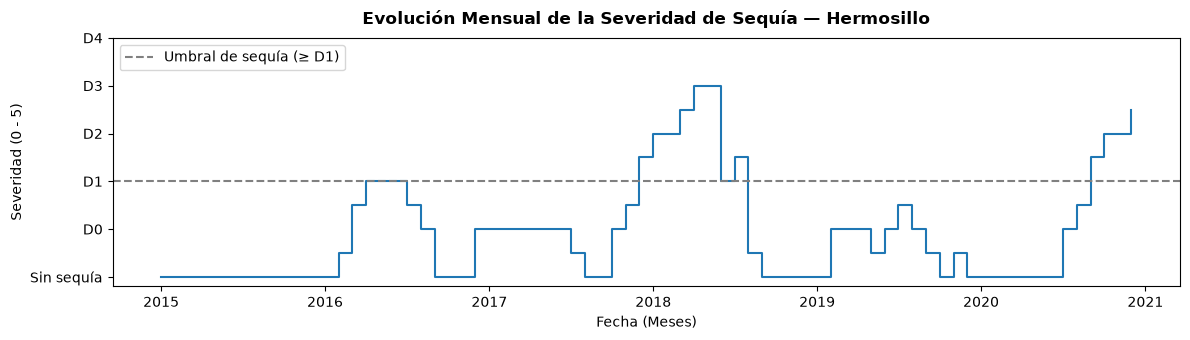

In [ ]:
plot_severidad_sequia_mensual(sequia_mensual)

## Serie semanal de sequía

In [9]:
sequia_semanal = drought_hermosillo_weekly()

# 1. Crear una serie de fechas semanales esperadas para el periodo completo
esperados_semanales = pd.date_range(f"{PANEL_START_YEAR}-01-01", f"{PANEL_END_YEAR}-12-31", freq="W")

# 2. Encontrar la diferencia con la columna de fecha semanal de tu dataset 
faltantes_semanales = esperados_semanales.difference(pd.to_datetime(sequia_semanal["fecha_semana"]))

# 3. Imprimir las semanas faltantes (puedes usar formato de fecha "%Y-%m-%d" o formato semana ISO "%Y-W%V")
print("Semanas del panel sin registro de sequía:", list(faltantes_semanales.strftime("%Y-%m-%d")))

sequia_semanal

Semanas del panel sin registro de sequía: ['2015-01-04', '2015-01-11', '2015-01-18', '2015-01-25', '2015-02-01', '2015-02-08', '2015-02-15', '2015-02-22', '2015-03-01', '2015-03-08', '2015-03-15', '2015-03-22', '2015-03-29', '2015-04-05', '2015-04-12', '2015-04-19', '2015-04-26', '2015-05-03', '2015-05-10', '2015-05-17', '2015-05-24', '2015-05-31', '2015-06-07', '2015-06-14', '2015-06-21', '2015-06-28', '2015-07-05', '2015-07-12', '2015-07-19', '2015-07-26', '2015-08-02', '2015-08-09', '2015-08-16', '2015-08-23', '2015-08-30', '2015-09-06', '2015-09-13', '2015-09-20', '2015-09-27', '2015-10-04', '2015-10-11', '2015-10-18', '2015-10-25', '2015-11-01', '2015-11-08', '2015-11-15', '2015-11-22', '2015-11-29', '2015-12-06', '2015-12-13', '2015-12-20', '2015-12-27', '2016-01-03', '2016-01-10', '2016-01-17', '2016-01-24', '2016-01-31', '2016-02-07', '2016-02-14', '2016-02-21', '2016-02-28', '2016-03-06', '2016-03-13', '2016-03-20', '2016-03-27', '2016-04-03', '2016-04-10', '2016-04-17', '2016

,fecha_semana,severidad_sequia,categoria_sequia
0,2015-01-12,0.0,Normal
1,2015-01-26,0.0,Normal
2,2015-02-09,0.0,Normal
3,2015-02-23,0.0,Normal
4,2015-03-09,0.0,Normal
...,...,...,...
139,2020-10-26,3.0,D2
140,2020-11-09,3.0,D2
141,2020-11-30,3.0,D2
142,2020-12-14,3.0,D2


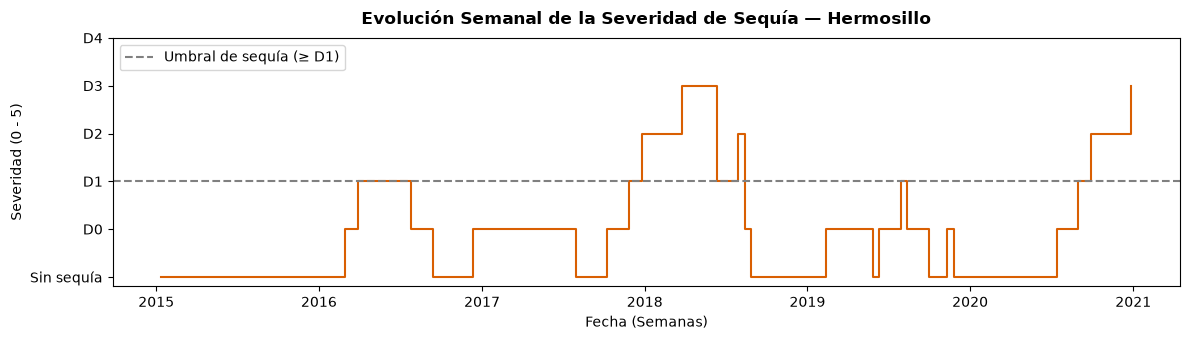

In [ ]:
plot_severidad_sequia_semanal(sequia_semanal)

## Guardar salida

In [11]:
# TODO: guardar una vez validada la serie
OUT_DIR.mkdir(parents=True, exist_ok=True)
sequia_mensual.to_csv(OUT_DIR / "sequia_hermosillo_mensual.csv", index=False)
sequia_semanal.to_csv(OUT_DIR / "sequia_hermosillo_semanal.csv", index=False)

## Decisiones de procesamiento

Registrar cada decisión que cambie los datos y su justificación. Si la
decisión cambia el panel, implementarla en `sonora_health_climate_eda/panel.py`
(es lo que ejecuta `03_eda/3.0-integracion-espacial.ipynb`) y llevarla al
reporte final.

| Variable / periodo | Problema | Decisión | Justificación |
|--------------------|----------|----------|---------------|
| Quincenal → mensual | Dos registros por mes | Severidad promedio + categoría modal | Se pierde el detalle de eventos cortos (limitación documentada) |
| _TODO_ | | | |